C:\Users\Harini.S\AppData\Local\Temp\ipykernel_28108\910993617.py:6: DtypeWarning: Columns (0: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("archive/cleaned_amazon_sales.csv")


Total Revenue by Category:
Category
Set              41165534.03
kurta            23211346.70
Western Dress    11697652.69
Top               5624277.30
Ethnic Dress       831147.66
Blouse             485633.18
Bottom             162767.98
Saree              129378.76
Dupatta               915.00
Name: Amount, dtype: float64

Top 5 Categories by Revenue:
Category
Set              41165534.03
kurta            23211346.70
Western Dress    11697652.69
Top               5624277.30
Ethnic Dress       831147.66
Name: Amount, dtype: float64

Bottom 5 Categories by Revenue:
Category
Dupatta            915.00
Saree           129378.76
Bottom          162767.98
Blouse          485633.18
Ethnic Dress    831147.66
Name: Amount, dtype: float64

Category-wise Quantity vs Revenue:
               Total_Quantity  Total_Revenue
Category                                    
Set                     45289    41165534.03
kurta                   45045    23211346.70
Western Dress           13943    11697652.69

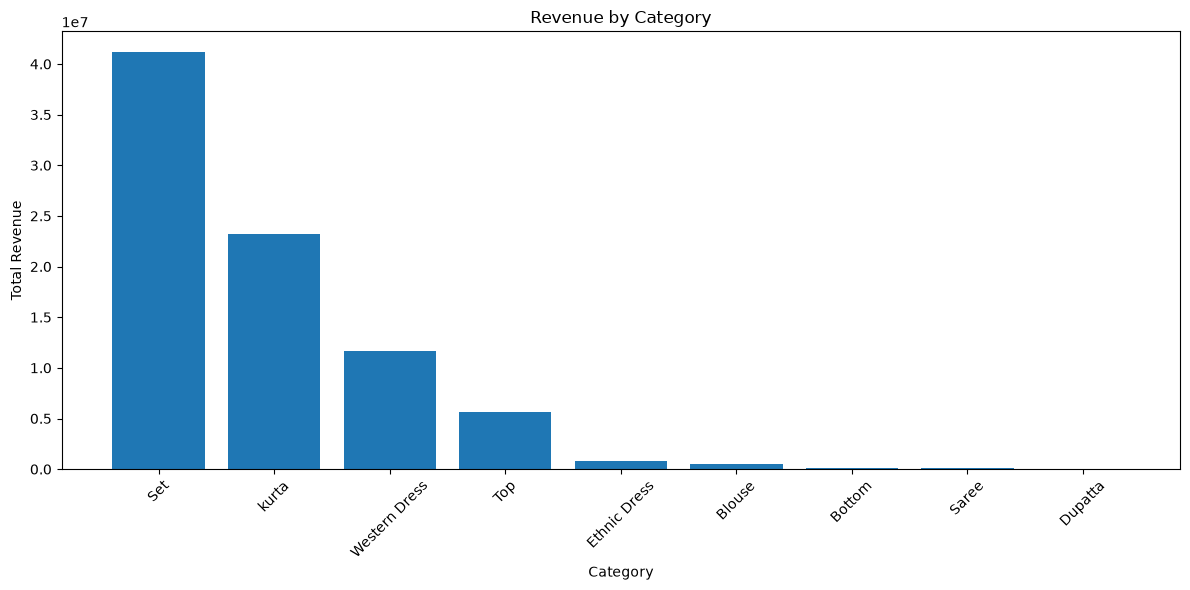


Category × Size × Quantity:
Size            3XL  4XL  5XL  6XL  Free     L     M     S    XL    XS   XXL
Category                                                                    
Blouse            0    0    0    0   211   128   138   128   116    25   117
Bottom           60    0    0    0     0    67    50    67    64    26    64
Dupatta           0    0    0    0     3     0     0     0     0     0     0
Ethnic Dress    160    0    0    0     0   170   167   163   173    77   143
Saree             0    0    0    0   152     0     0     0     0     0     0
Set            5287   46   57   72     0  7399  8357  6708  6873  4882  5608
Top            1122    0    0    0     0  1647  1696  1146  1734   870  1688
Western Dress  1760    0    0    0     0  2546  2326  1962  2125  1280  1944
kurta          5135  352  456  616     0  8043  7713  5157  7838  2783  6952

Most Popular Size per Category:
Category
Blouse           Free
Bottom              L
Dupatta          Free
Ethnic Dress    

In [2]:
# Task 4: Category & Product Performance

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("archive/cleaned_amazon_sales.csv")

# 1. Calculate total revenue by category
category_revenue = df.groupby("Category")["Amount"].sum().sort_values(ascending=False)

print("Total Revenue by Category:")
print(category_revenue)


# 2. Top 5 categories by total revenue
top_5_categories = category_revenue.head(5)

print("\nTop 5 Categories by Revenue:")
print(top_5_categories)


# 3. Bottom 5 categories by total revenue
bottom_5_categories = category_revenue.tail(5).sort_values()

print("\nBottom 5 Categories by Revenue:")
print(bottom_5_categories)


# 4. Analyze quantity sold vs revenue per category
category_performance = df.groupby("Category").agg(
    Total_Quantity=("Qty", "sum"),
    Total_Revenue=("Amount", "sum")
).sort_values("Total_Revenue", ascending=False)

print("\nCategory-wise Quantity vs Revenue:")
print(category_performance)


# 5. Bar chart of revenue by category
plt.figure(figsize=(12, 6))

plt.bar(
    category_revenue.index,
    category_revenue.values
)

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# 6. Create Category × Size × Quantity pivot table
category_size_quantity = pd.pivot_table(
    df,
    values="Qty",
    index="Category",
    columns="Size",
    aggfunc="sum",
    fill_value=0
)

print("\nCategory × Size × Quantity:")
print(category_size_quantity)


# 7. Identify most popular size per category
most_popular_size = category_size_quantity.idxmax(axis=1)

print("\nMost Popular Size per Category:")
print(most_popular_size)